# 2 · Data Understanding — RoadAnomaly

**CRISP-DM phase 2.** Previous: [`1_Business_Understanding.md`](1_Business_Understanding.md) · Next: [`3_Data_Preparation.ipynb`](3_Data_Preparation.ipynb)

What this notebook does: it describes the 60 images and their pixel masks (structure, integrity, labels, class imbalance, objects, resolution, scenes that belong together, normal data for the autoencoder) and derives the **evaluation protocol** from these measurements (section 10).

Rule followed here: **no metric or benchmark is chosen in advance.** Every choice of the protocol is derived from a measurement made in sections 1–9. The protocol constants are then written once in `src/roadanomaly/protocol.py`, so every notebook and script uses the same values.

Shared code used here (`pip install -e .`): `roadanomaly.data_pipeline` (frames, binary masks), `roadanomaly.splitting` (scene groups), `roadanomaly.gpu`.

## TL;DR — what the data told us, and what we decided because of it

Picture 60 "spot the odd one out" photographs: a cow, a rock, a cone or a lost tyre on a road, with the odd thing painted pixel by pixel. Before choosing any model or metric, we measured what these photographs are like. Each measurement forced one rule of the protocol (section 10):

| What we measured | Why it matters, in plain words | So we decided |
|---|---|---|
| Only **9.85 %** of the pixels are obstacle (§5) | A model that says "no obstacle anywhere" is already **90 % accurate**, and useless | Pixel accuracy is banned. The main score is **AuPRC**, whose "blind guess" level is the obstacle share itself (about 0.09), so beating it means something |
| Obstacles go from **16 px to 390,000 px**, half are under 1,000 px, and **36 of 60** photos have several (§6) | A model can colour the big cow perfectly, miss three small cones, and still get a good pixel score | Count **obstacles** too: how many are found (object recall) and how many alarms are false (object precision) |
| **Every** photo contains an obstacle, but **69 %** of the 64×64 tiles contain none (§5, §9) | The autoencoder needs "normal road" to learn from, and there is no clean photo | It learns from the obstacle-free **tiles** of the training photos; no external data |
| Some photos are **frames of the same video** (§8) | If one frame is in training and its twin in the test, the test checks memory, not understanding | A **group-aware** split: the 60 photos form 51 scene groups that never cross splits |
| At **352×640**, 89.5 % of obstacles keep at least 16 px (§7) | Smaller images erase small obstacles; bigger ones do not fit a 6 GB GPU | Every model works at **352×640** (both sides divisible by 32) |
| Validation and test have **9 photos each** (§10) | One photo more or less moves an average by about 11 % | Every test score gets a **95 % bootstrap interval**; no winner is declared when the intervals overlap |

The constants of these decisions live once in `src/roadanomaly/protocol.py`, so the three binômes cannot measure differently.

## 0. Setup

In [1]:
# Import libraries
import os

# hide TensorFlow C++ log lines (e.g. the harmless "use_unbounded_threadpool" notice)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import random
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
import tensorflow as tf
from IPython.display import display
from PIL import Image
from scipy import ndimage

tf.get_logger().setLevel("ERROR")                    # hide tf.function retracing notices

# Make the repository's src/ package importable from the notebook kernel.
REPO_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src" / "roadanomaly").is_dir()),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError(
        "Could not find src/roadanomaly from the notebook working directory. "
        "Open the notebook from the repository, or install the project with `pip install -e .`."
    )

source_dir = str(REPO_ROOT / "src")
if source_dir not in sys.path:
    sys.path.insert(0, source_dir)

import warnings

from roadanomaly import data_pipeline as dp
from roadanomaly.gpu import setup_gpu

warnings.filterwarnings('ignore')

In [2]:
# Constants and seeds for reproducibility
SEED = 42                      # only for random examples shown in this notebook
DATA_DIR = dp.DATA_DIR
FRAMES_DIR = DATA_DIR / "frames"
FIG_DIR = dp.FIG_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

GPU_NAME = setup_gpu()
print("TensorFlow:", tf.__version__)
print("Dataset folder:", DATA_DIR.relative_to(dp.REPO_ROOT))

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | compute capability: (8, 9)
TensorFlow: 2.20.0
Dataset folder: data/raw/RoadAnomaly


## 1. Dataset structure, sources and licences

RoadAnomaly was introduced by Lis, Nakka, Fua and Salzmann in *Detecting the Unexpected via Image Resynthesis* (ICCV 2019; [EPFL record](https://infoscience.epfl.ch/record/269093)). The dataset description is in [`data/raw/RoadAnomaly/readme.md`](../data/raw/RoadAnomaly/readme.md). The authors and source URLs for individual images, together with image-specific licence information, are listed in [`data/raw/RoadAnomaly/credits.txt`](../data/raw/RoadAnomaly/credits.txt). The annotations are documented as CC BY-SA 4.0.

**Use conditions:** the project does not own the images. Check the relevant entry in `credits.txt` before reusing or redistributing an image; the annotation licence does not replace the image licence. Cite the paper when using the dataset.


### Data dictionary and target labels

| Field / file | Meaning | Use in this project |
|---|---|---|
| `frame` | Image identifier without extension | Joins image, annotations and split. |
| `category` | Category inferred from the filename prefix | Descriptive metadata such as animals or cones; **not** a pixel-level target class. |
| `scene_group` | Related images grouped by scene or source | Kept together when creating data splits to reduce leakage. |
| `split` | `train`, `val` or `test` | Test data is reserved for final comparison. |
| `*.webp` | RGB input image | Converted by the shared loader to float values in `[0, 1]`. |
| `labels_semantic.png` | Pixel-wise semantic annotation | `0` = background; `2` = anomaly. The pipeline converts this to a binary mask. |
| `labels_instance.png` | Instance IDs, when available | Missing for some frames; not used as the common ground truth. |

**Task definition:** this dataset supports binary pixel-level anomaly segmentation (background vs. anomaly). The filename categories do not mean the semantic masks distinguish animals, cones, rocks, and other anomaly types.


In [3]:
# Read the dataset readme
print((DATA_DIR / "readme.md").read_text()[:1500])

 
# Road Anomaly dataset

![](frames/animals06_sheep_roads_lambs.webp)

This dataset contains images of unusual dangers which can be encountered by a vehicle on the road - animals, rocks, traffic cones and other obstacles.
Its purpose is testing autonomous driving perception algorithms in rare but safety-critical circumstances.

The dataset contains images with associated per-pixel labels.
The labeling has been performed with our [LabelGrab](github.com/cvlab-epfl/LabelGrab) tool. Most frames retain the editor's files and can be further edited; some are missing because the labeling was done at a different resolution and rescaled. 
If you need the editor files and instance labels for all frames, please [contact us](mailto:krzysztof.lis@epfl.ch).

For any additional information, please contact [Krzysztof Lis](mailto:krzysztof.lis@epfl.ch).

The images are provided for research purposes.
We do not own the images; the authors and sources are listed in `credits.txt`.

### Directory structure

In [4]:
# Compare frame_list.json with the files actually on disk
frames = dp.list_frames()
on_disk = sorted(p.stem for p in FRAMES_DIR.glob("*.webp"))
print("Frames in frame_list.json:", len(frames))
print("WebP images on disk      :", len(on_disk))
print("Listed but missing       :", sorted(set(frames) - set(on_disk)))
print("On disk but not listed   :", sorted(set(on_disk) - set(frames)))
print("Duplicate names in list  :", [f for f, c in Counter(frames).items() if c > 1])

Frames in frame_list.json: 60
WebP images on disk      : 60
Listed but missing       : []
On disk but not listed   : []
Duplicate names in list  : []


In [5]:
# Which files exist in each .labels folder
rows = []
for frame in frames:
    labels_dir = FRAMES_DIR / f"{frame}.labels"
    rows.append({
        "frame": frame,
        "category": dp.category_of(frame),
        "labels_semantic": (labels_dir / "labels_semantic.png").exists(),
        "labels_semantic_color": (labels_dir / "labels_semantic_color.png").exists(),
        "labels_instance": (labels_dir / "labels_instance.png").exists(),
        "index_json": (labels_dir / "index.json").exists(),
        "credited": frame in (DATA_DIR / "credits.txt").read_text(),
    })
files_df = pd.DataFrame(rows)
print(files_df.drop(columns=["frame", "category"]).sum().to_string())
print()
print("Images per category:")
print(files_df["category"].value_counts().to_string())

labels_semantic          60
labels_semantic_color    60
labels_instance          46
index_json               46
credited                 60

Images per category:
category
animals       31
obstacles     15
cones          8
lost_tires     3
vehicle        3


## 2. Image / mask integrity

In [6]:
# Check dimensions, labels, and readability for each image / mask pair
rows = []
unreadable_files = []
for frame in frames:
    image_path = FRAMES_DIR / f"{frame}.webp"
    labels_path = FRAMES_DIR / f"{frame}.labels" / "labels_semantic.png"
    color_path = FRAMES_DIR / f"{frame}.labels" / "labels_semantic_color.png"
    try:
        with Image.open(image_path) as image:
            image.load()
            image_size, image_mode = image.size, image.mode
        with Image.open(labels_path) as labels:
            labels.load()
            mask_size, mask_mode = labels.size, labels.mode
            labels_arr = np.array(labels)
        with Image.open(color_path) as color_image:
            color_image.load()
            color = np.array(color_image.convert("RGB"))
    except (OSError, ValueError, SyntaxError, EOFError) as exc:
        unreadable_files.append({"frame": frame, "error": f"{type(exc).__name__}: {exc}"})
        continue

    # The colour mask must mark exactly the same pixels as the semantic mask.
    color_anomaly = np.any(color != color[labels_arr == 0][0], axis=-1) if np.any(labels_arr == 0) else None
    rows.append({
        "frame": frame,
        "image_size": image_size,
        "image_mode": image_mode,
        "mask_size": mask_size,
        "mask_mode": mask_mode,
        "label_values": tuple(np.unique(labels_arr).tolist()),
        "color_matches_semantic": bool(np.array_equal(color_anomaly, labels_arr == dp.ANOMALY_LABEL)),
    })
integrity_df = pd.DataFrame(rows)
print("Image sizes   :", Counter(integrity_df["image_size"]))
print("Image modes   :", Counter(integrity_df["image_mode"]))
print("Mask sizes    :", Counter(integrity_df["mask_size"]))
print("Mask modes    :", Counter(integrity_df["mask_mode"]))
print("Label values  :", Counter(integrity_df["label_values"]))
print("Image size == mask size for readable pairs:", (integrity_df["image_size"] == integrity_df["mask_size"]).all())
print("Colour mask agrees with semantic mask:", integrity_df["color_matches_semantic"].sum(), "/", len(integrity_df))


Image sizes   : Counter({(1280, 720): 60})
Image modes   : Counter({'RGB': 60})
Mask sizes    : Counter({(1280, 720): 60})
Mask modes    : Counter({'L': 60})
Label values  : Counter({(0, 2): 60})
Image size == mask size for readable pairs: True
Colour mask agrees with semantic mask: 60 / 60


In [7]:
# Summarize dataset size and data-quality checks before continuing
label_values_ok = all(set(values).issubset({0, 2}) for values in integrity_df["label_values"])
dataset_files = [item for item in DATA_DIR.rglob("*") if item.is_file()]
dataset_size_bytes = sum(item.stat().st_size for item in dataset_files)
print(f"Dataset size on disk: {dataset_size_bytes / (1024 ** 2):.2f} MiB ({len(dataset_files)} files)")

quality_rows = [
    ("Unique frame names", len(frames) == len(set(frames)), f"{len(frames) - len(set(frames))} duplicate(s)"),
    (
        "frame_list.json matches WebP files",
        set(frames) == set(on_disk),
        f"{len(set(frames) - set(on_disk))} missing; {len(set(on_disk) - set(frames))} unlisted",
    ),
    (
        "Semantic masks present",
        bool(files_df["labels_semantic"].all()),
        f"{int((~files_df['labels_semantic']).sum())} missing",
    ),
    (
        "Image/mask dimensions agree",
        bool((integrity_df["image_size"] == integrity_df["mask_size"]).all()),
        f"{int((integrity_df['image_size'] != integrity_df['mask_size']).sum())} mismatch(es)",
    ),
    (
        "Semantic label values are valid (0, 2)",
        label_values_ok,
        "Observed: " + str(sorted({value for values in integrity_df["label_values"] for value in values})),
    ),
    (
        "Color and semantic masks agree",
        bool(integrity_df["color_matches_semantic"].all()),
        f"{int((~integrity_df['color_matches_semantic']).sum())} disagreement(s)",
    ),
    ("Images and masks are readable", not unreadable_files, f"{len(unreadable_files)} unreadable/corrupt pair(s)"),
]
quality_report = pd.DataFrame(quality_rows, columns=["Check", "OK", "Details"])
quality_report["Status"] = quality_report["OK"].map({True: "OK", False: "Investigate"})
display(quality_report[["Check", "Status", "Details"]])
if unreadable_files:
    display(pd.DataFrame(unreadable_files))
    raise RuntimeError("Unreadable/corrupt image or mask files were found; resolve them before continuing.")

Dataset size on disk: 12.53 MiB (677 files)


,Check,Status,Details
0,Unique frame names,OK,0 duplicate(s)
1,frame_list.json matches WebP files,OK,0 missing; 0 unlisted
2,Semantic masks present,OK,0 missing
3,Image/mask dimensions agree,OK,0 mismatch(es)
4,"Semantic label values are valid (0, 2)",OK,"Observed: [0, 2]"
5,Color and semantic masks agree,OK,0 disagreement(s)
6,Images and masks are readable,OK,0 unreadable/corrupt pair(s)


## 3. Label table

In [8]:
# Colours used in labels_semantic_color.png for each semantic value
frame = frames[0]
labels_arr = np.array(Image.open(FRAMES_DIR / f"{frame}.labels" / "labels_semantic.png"))
color = np.array(Image.open(FRAMES_DIR / f"{frame}.labels" / "labels_semantic_color.png").convert("RGB"))
label_table = pd.DataFrame([
    {"semantic value": v,
     "meaning": {0: "background (road, sky, vegetation, ...)", 2: "anomaly (unexpected object)"}[v],
     "colour in _color.png": tuple(color[labels_arr == v][0].tolist()),
     "binary target": int(v == dp.ANOMALY_LABEL)}
    for v in np.unique(labels_arr)
])
label_table

,semantic value,meaning,colour in _color.png,binary target
0,0,"background (road, sky, vegetation, ...)","(0, 0, 0)",0
1,2,anomaly (unexpected object),"(255, 69, 0)",1


## 4. Visual examples (one row per category)

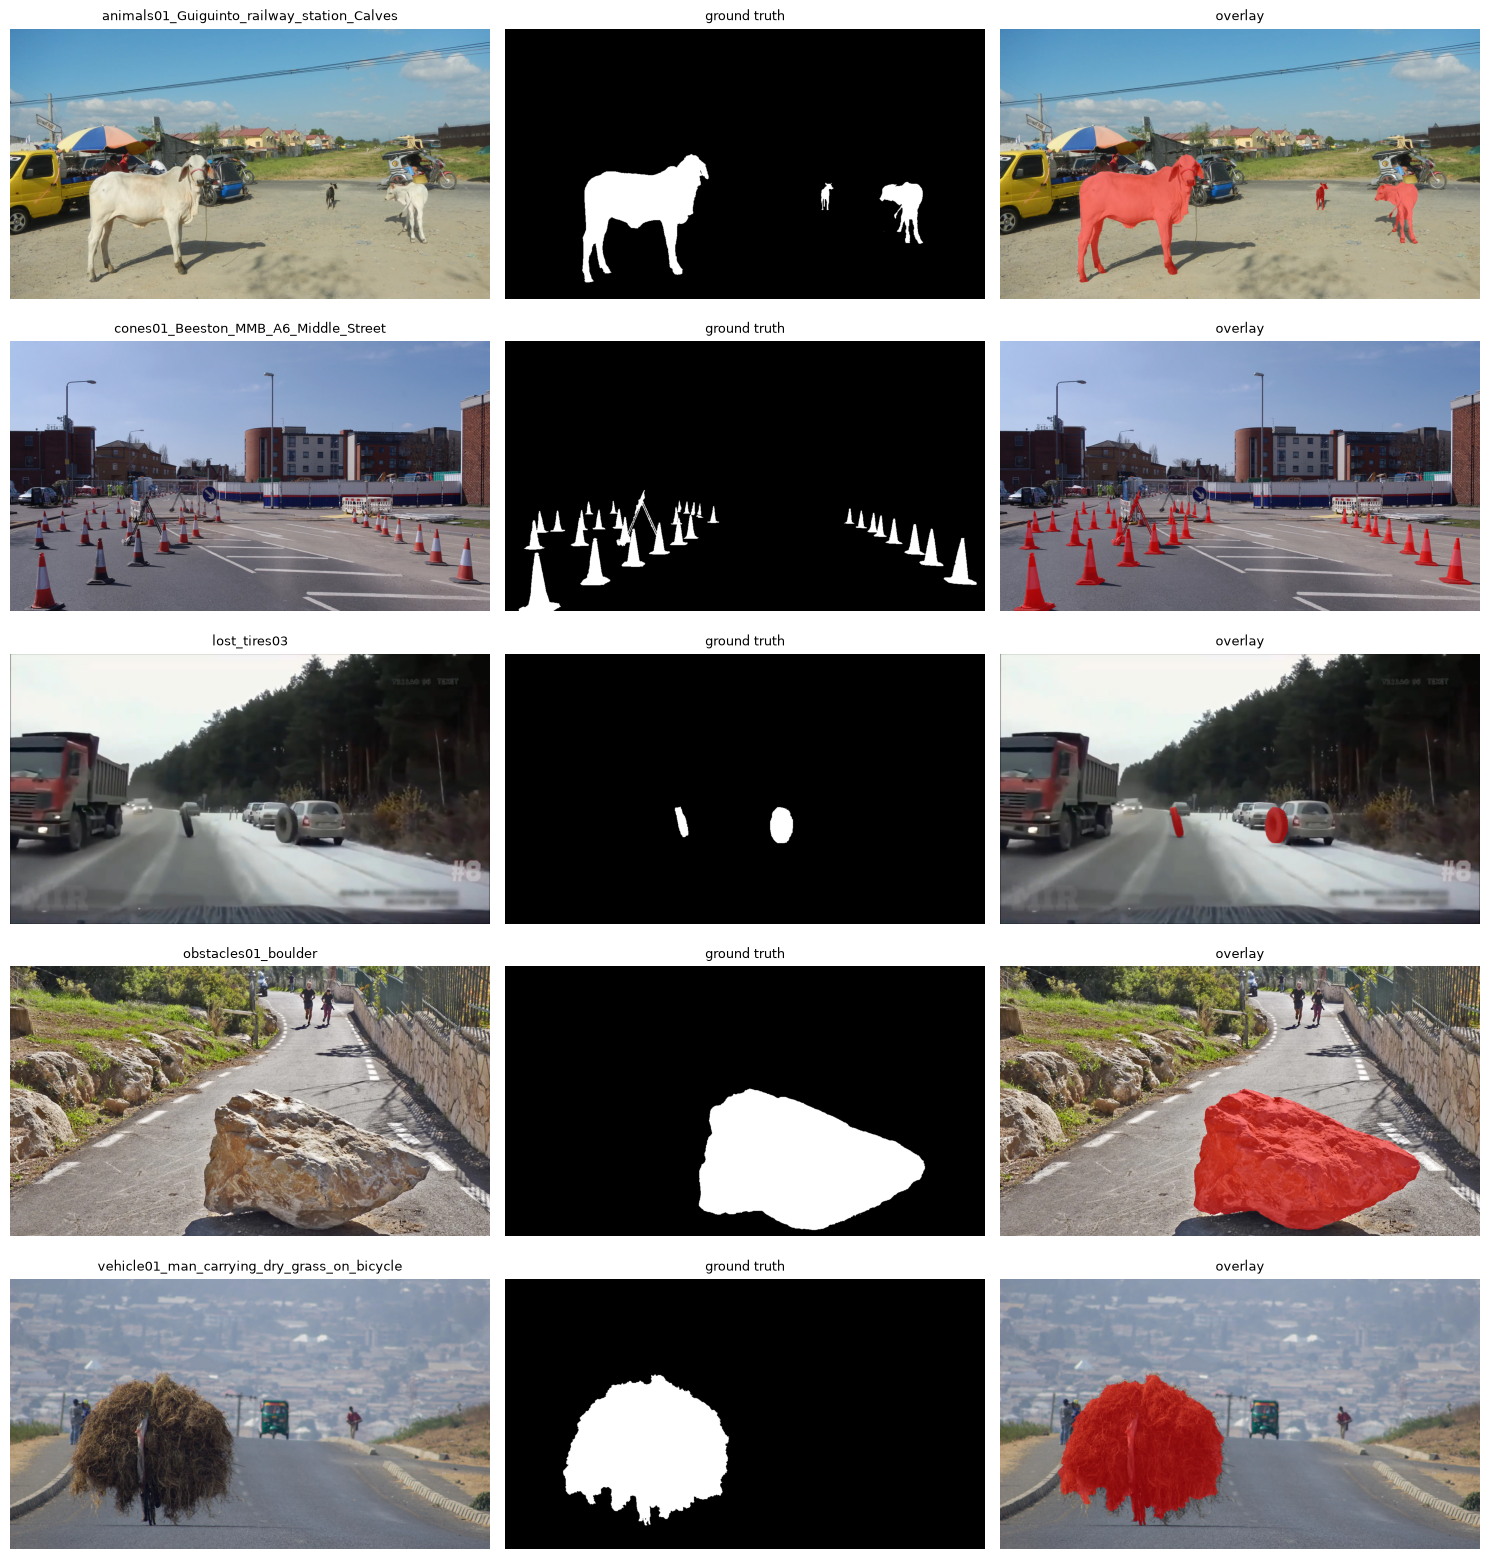

In [9]:
# Show image | mask | overlay for the first frame of each category
categories = sorted(files_df["category"].unique())
fig, ax = plt.subplots(len(categories), 3, figsize=(15, 3.2 * len(categories)), tight_layout=True)
for i, category in enumerate(categories):
    frame = files_df.loc[files_df["category"] == category, "frame"].iloc[0]
    image, mask = dp.load_frame(frame)
    overlay = image.copy()
    overlay[mask == 1] = (0.5 * overlay[mask == 1] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    for j, (panel, title) in enumerate([(image, frame), (mask, "ground truth"), (overlay, "overlay")]):
        ax[i, j].imshow(panel, cmap="gray" if panel.ndim == 2 else None)
        ax[i, j].set_title(title, fontsize=9)
        ax[i, j].axis("off")
plt.savefig(FIG_DIR / "01_examples_per_category.png", dpi=80)
plt.show()

## 5. Class imbalance (anomaly pixel ratio)
How many pixels of each image belong to the anomaly. This decides whether pixel accuracy or AUROC would be misleading.

In [10]:
# Load all binary masks at full resolution
masks_full = {frame: dp.load_frame(frame)[1] for frame in frames}
stats_df = files_df[["frame", "category"]].copy()
stats_df["anomaly_ratio"] = [masks_full[f].mean() for f in frames]
stats_df["has_anomaly"] = stats_df["anomaly_ratio"] > 0

total_ratio = np.sum([m.sum() for m in masks_full.values()]) / np.sum([m.size for m in masks_full.values()])
print("Images with at least one anomaly pixel:", stats_df["has_anomaly"].sum(), "/", len(stats_df))
print(f"Anomaly pixels over the whole dataset : {100 * total_ratio:.2f} %")
print(f"Accuracy of a model that predicts 'all background': {100 * (1 - total_ratio):.2f} %")
print()
print(stats_df["anomaly_ratio"].describe(percentiles=[.1, .25, .5, .75, .9]).apply(lambda v: f"{v:.4f}").to_string())

Images with at least one anomaly pixel: 60 / 60
Anomaly pixels over the whole dataset : 9.85 %
Accuracy of a model that predicts 'all background': 90.15 %

count    60.0000
mean      0.0985
std       0.1006
min       0.0037
10%       0.0109
25%       0.0180
50%       0.0662
75%       0.1380
90%       0.2351
max       0.4233


In [11]:
# Anomaly ratio per category
print(stats_df.groupby("category")["anomaly_ratio"].agg(["count", "mean", "median", "min", "max"]).round(4).to_string())

            count    mean  median     min     max
category                                         
animals        31  0.1267  0.0820  0.0080  0.4233
cones           8  0.0288  0.0172  0.0110  0.0656
lost_tires      3  0.0069  0.0070  0.0037  0.0099
obstacles      15  0.0950  0.0631  0.0063  0.2468
vehicle         3  0.1020  0.0997  0.0768  0.1295


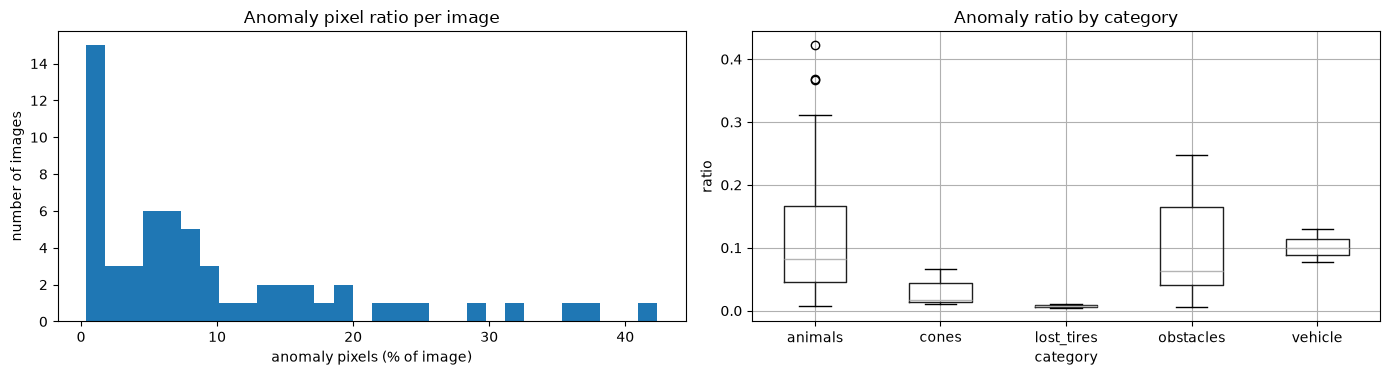

In [12]:
# Histogram of the anomaly ratio per image
fig, ax = plt.subplots(1, 2, figsize=(14, 4), tight_layout=True)
ax[0].hist(100 * stats_df["anomaly_ratio"], bins=30)
ax[0].set_xlabel("anomaly pixels (% of image)")
ax[0].set_ylabel("number of images")
ax[0].set_title("Anomaly pixel ratio per image")
stats_df.boxplot(column="anomaly_ratio", by="category", ax=ax[1])
ax[1].set_title("Anomaly ratio by category")
ax[1].set_ylabel("ratio")
plt.suptitle("")
plt.savefig(FIG_DIR / "02_anomaly_ratio.png", dpi=80)
plt.show()

## 6. Object level: how many obstacles, how big, where
Each 8-connected component of the binary mask is a candidate obstacle. Before counting obstacles we must check whether every component really is one.

In [13]:
# Connected components of every mask (full resolution 1280x720)
H, W = next(iter(masks_full.values())).shape
component_rows = []
for frame in frames:
    labeled, n = ndimage.label(masks_full[frame], structure=np.ones((3, 3)))
    for k, sl in enumerate(ndimage.find_objects(labeled), start=1):
        comp = labeled[sl] == k
        ys, xs = np.nonzero(comp)
        component_rows.append({
            "frame": frame,
            "category": dp.category_of(frame),
            "label_id": k,
            "area_px": int(comp.sum()),
            "bbox_h": sl[0].stop - sl[0].start,
            "bbox_w": sl[1].stop - sl[1].start,
            "centroid_y": (sl[0].start + ys.mean()) / H,   # 0 = top of the image, 1 = bottom
            "centroid_x": (sl[1].start + xs.mean()) / W,
        })
comp_df = pd.DataFrame(component_rows)
print("Total components:", len(comp_df))
print(comp_df["area_px"].describe(percentiles=[.1, .25, .5, .75, .9]).round(0).to_string())

Total components: 298
count       298.0
mean      18277.0
std       50722.0
min           1.0
10%           1.0
25%          45.0
50%         427.0
75%        8630.0
90%       48031.0
max      390065.0


The 10th percentile of the component area is a handful of pixels: some components are far too small to be obstacles. The histogram of log-areas below shows whether they form a separate population.

        1 -         2 px : ###################################### 38
        2 -         3 px : ############### 15
        3 -         6 px : ### 3
        6 -        10 px : ## 2
       10 -        18 px : ## 2
       18 -        32 px : ###### 6
       32 -        56 px : ################ 16
       56 -       100 px : ####################### 23
      100 -       178 px : ################### 19
      178 -       316 px : ################# 17
      316 -       562 px : #################### 20
      562 -      1000 px : ################ 16
     1000 -      1778 px : ############### 15
     1778 -      3162 px : ############ 12
     3162 -      5623 px : ########### 11
     5623 -     10000 px : ################# 17
    10000 -     17783 px : ################ 16
    17783 -     31623 px : ########## 10
    31623 -     56234 px : ############## 14
    56234 -    100000 px : ######## 8
   100000 -    177828 px : ######### 9
   177828 -    316228 px : ####### 7
   316228 -    562341 px : ##

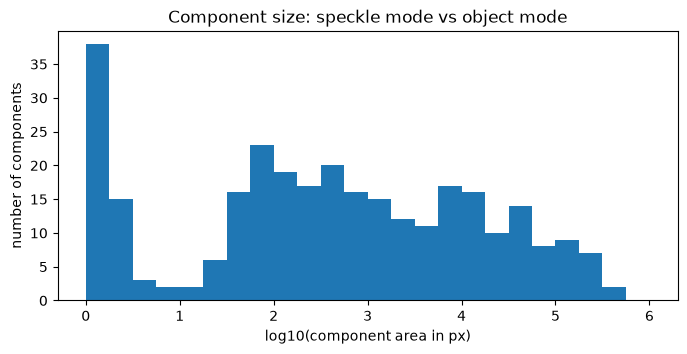

In [14]:
# Histogram of component sizes on a log scale
log_area = np.log10(comp_df["area_px"])
bins = np.arange(0, 6.25, 0.25)
counts, edges = np.histogram(log_area, bins=bins)
for c, e in zip(counts, edges, strict=False):
    print(f"{10**e:>9.0f} - {10**(e + 0.25):>9.0f} px : {'#' * c} {c}")

plt.figure(figsize=(8, 3.5))
plt.hist(log_area, bins=bins)
plt.xlabel("log10(component area in px)")
plt.ylabel("number of components")
plt.title("Component size: speckle mode vs object mode")
plt.savefig(FIG_DIR / "03_component_size_hist.png", dpi=80)
plt.show()

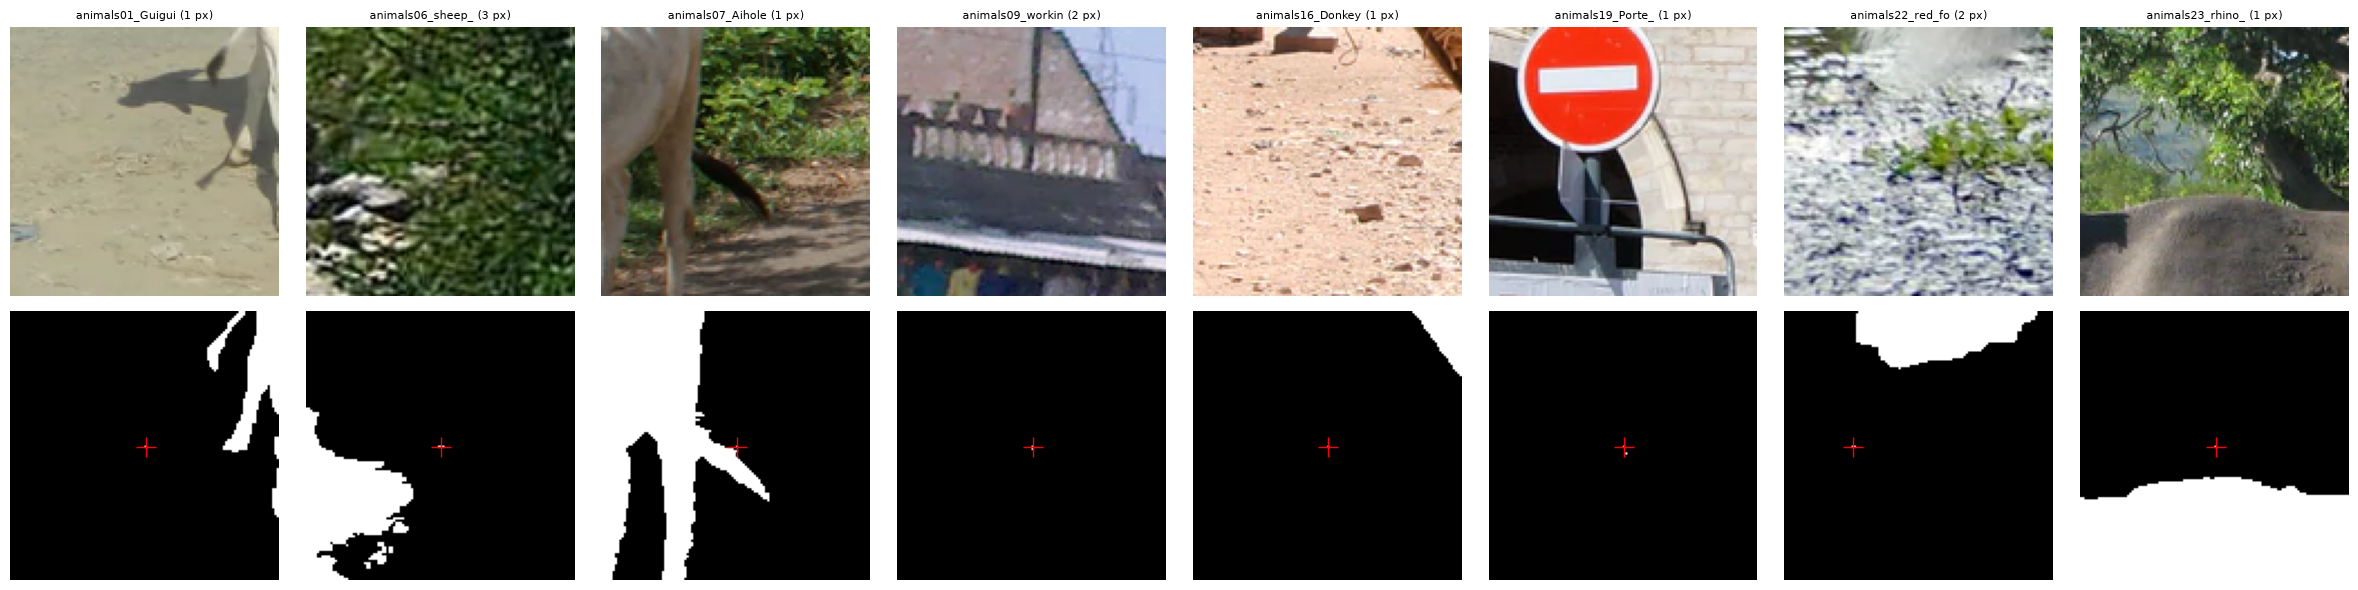

In [15]:
# Look at the tiny components in the image: are they obstacles or annotation noise?
tiny = comp_df[comp_df["area_px"] <= 16].groupby("frame").head(1).head(8)
fig, ax = plt.subplots(2, len(tiny), figsize=(3 * len(tiny), 6), tight_layout=True)
for i, row in enumerate(tiny.itertuples()):
    image, mask = dp.load_frame(row.frame)
    cy, cx = int(row.centroid_y * H), int(row.centroid_x * W)
    y0, x0 = max(cy - 60, 0), max(cx - 60, 0)
    ax[0, i].imshow(image[y0:y0 + 120, x0:x0 + 120])
    ax[0, i].set_title(f"{row.frame[:16]} ({row.area_px} px)", fontsize=8)
    ax[1, i].imshow(mask[y0:y0 + 120, x0:x0 + 120], cmap="gray")
    ax[1, i].plot(cx - x0, cy - y0, "r+", ms=14)
    ax[0, i].axis("off")
    ax[1, i].axis("off")
plt.savefig(FIG_DIR / "04_annotation_speckle.png", dpi=70)
plt.show()

In [16]:
# Threshold placed in the empty valley of the histogram, between the two modes
MIN_OBJECT_PX = 16   # at 1280x720

comp_df["is_object"] = comp_df["area_px"] >= MIN_OBJECT_PX
speckle = comp_df[~comp_df["is_object"]]
total_anomaly_px = comp_df["area_px"].sum()
print(
    f"Speckle components (< {MIN_OBJECT_PX} px): {len(speckle)} "
    f"({100 * len(speckle) / len(comp_df):.1f} % of components)"
    f" in {speckle['frame'].nunique()} images, holding "
    f"{100 * speckle['area_px'].sum() / total_anomaly_px:.4f} % of the anomaly pixels"
)
objects_df = comp_df[comp_df["is_object"]].copy()
print("Real objects:", len(objects_df))

Speckle components (< 16 px): 59 (19.8 % of components) in 16 images, holding 0.0021 % of the anomaly pixels
Real objects: 239


**Decision:** the ground truth is **not modified** (speckle is a negligible share of the pixels, so pixel metrics do not change). For everything that counts *objects* (statistics below, object-level metrics, boundary metrics) components smaller than `MIN_OBJECT_PX` are ignored.

In [17]:
# Objects per image and object sizes (speckle excluded)
stats_df["n_objects"] = stats_df["frame"].map(objects_df.groupby("frame").size()).fillna(0).astype(int)
print("Objects per image:", sorted(Counter(stats_df["n_objects"]).items()))
print(f"Images with more than one object: {(stats_df['n_objects'] > 1).sum()} / {len(stats_df)}")
print()
print("Object area (px at 1280x720):")
print(objects_df["area_px"].describe(percentiles=[.1, .25, .5, .75, .9]).round(0).to_string())
for limit in [100, 1000, 10000]:
    print(
        f"objects smaller than {limit:>6} px ({100 * limit / (H * W):.3f} % of the image): "
        f"{100 * (objects_df['area_px'] < limit).mean():5.1f} %"
    )
print()
largest_share = objects_df.groupby("frame")["area_px"].agg(lambda a: a.max() / a.sum())
print(f"In multi-object images, the largest object holds on average "
      f"{100 * largest_share[stats_df.set_index('frame')['n_objects'] > 1].mean():.1f} % of the anomaly pixels")

Objects per image: [(1, 24), (2, 13), (3, 8), (4, 3), (5, 2), (6, 1), (7, 1), (8, 2), (10, 1), (12, 1), (18, 1), (20, 1), (22, 1), (32, 1)]
Images with more than one object: 36 / 60

Object area (px at 1280x720):
count       239.0
mean      22788.0
std       55743.0
min          16.0
10%          60.0
25%         166.0
50%        1112.0
75%       12970.0
90%       66853.0
max      390065.0
objects smaller than    100 px (0.011 % of the image):  19.2 %
objects smaller than   1000 px (0.109 % of the image):  49.4 %
objects smaller than  10000 px (1.085 % of the image):  72.4 %

In multi-object images, the largest object holds on average 68.0 % of the anomaly pixels


In [18]:
# Annotated instances (labels_instance.png, 46 frames) vs objects found as components
rows = []
for frame in frames:
    path = FRAMES_DIR / f"{frame}.labels" / "labels_instance.png"
    if path.exists():
        inst = np.array(Image.open(path))
        rows.append({"frame": frame, "instances": len(np.unique(inst[inst > 0])),
                     "objects": int(stats_df.loc[stats_df["frame"] == frame, "n_objects"].iloc[0])})
inst_df = pd.DataFrame(rows)
print("Instances == objects:", (inst_df["instances"] == inst_df["objects"]).sum(), "/", len(inst_df))
print(
    "Instances >  objects (touching instances merge into one component):",
    (inst_df["instances"] > inst_df["objects"]).sum(),
)
print("Instances <  objects (one instance split into pieces):", (inst_df["instances"] < inst_df["objects"]).sum())

Instances == objects: 26 / 46
Instances >  objects (touching instances merge into one component): 13
Instances <  objects (one instance split into pieces): 7


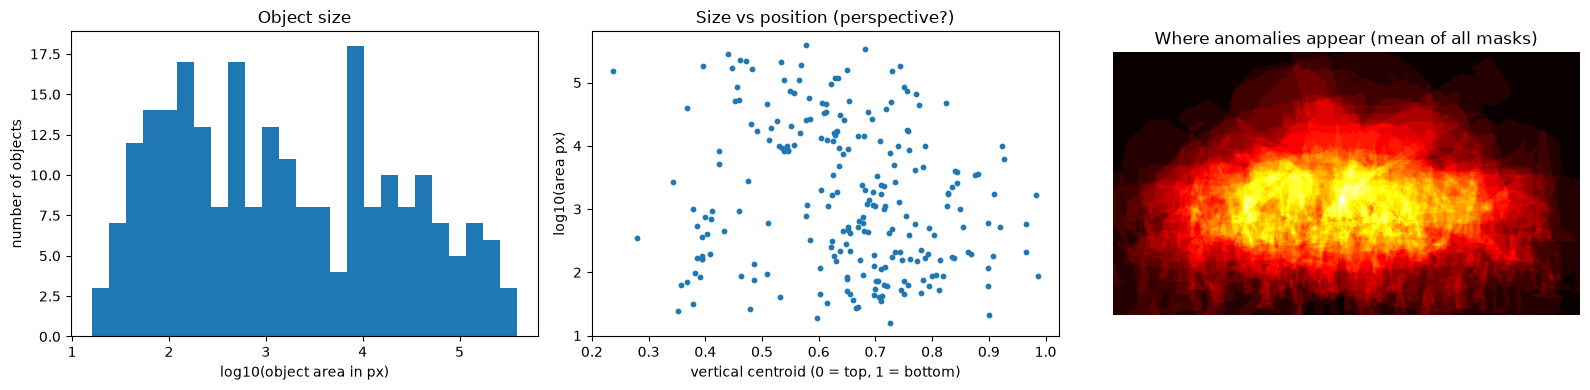

Correlation between vertical position and log-area: -0.183
Vertical centroid of objects: median 0.66 | share in the top third of the image: 0.008


In [19]:
# Size and vertical position of the objects
fig, ax = plt.subplots(1, 3, figsize=(16, 4), tight_layout=True)
ax[0].hist(np.log10(objects_df["area_px"]), bins=25)
ax[0].set_xlabel("log10(object area in px)")
ax[0].set_ylabel("number of objects")
ax[0].set_title("Object size")
ax[1].scatter(objects_df["centroid_y"], np.log10(objects_df["area_px"]), s=10)
ax[1].set_xlabel("vertical centroid (0 = top, 1 = bottom)")
ax[1].set_ylabel("log10(area px)")
ax[1].set_title("Size vs position (perspective?)")
heat = np.mean(np.stack(list(masks_full.values())), axis=0)
ax[2].imshow(heat, cmap="hot")
ax[2].set_title("Where anomalies appear (mean of all masks)")
ax[2].axis("off")
plt.savefig(FIG_DIR / "05_objects.png", dpi=80)
plt.show()
print("Correlation between vertical position and log-area:",
      round(np.corrcoef(objects_df["centroid_y"], np.log10(objects_df["area_px"]))[0, 1], 3))
print("Vertical centroid of objects: median", round(objects_df["centroid_y"].median(), 2),
      "| share in the top third of the image:", round((objects_df["centroid_y"] < 1 / 3).mean(), 3))

## 7. Resolution study
Training at 1280x720 does not fit the 6 GB RTX 2060 for most models, so the images must be downscaled, and downscaling erases small obstacles. For each candidate size (all keep the 16:9 aspect ratio, so obstacles are not distorted) we count how many **real objects** keep a usable number of pixels.

In [20]:
# Pixels left for each real object after nearest-neighbour downscaling
CANDIDATE_SIZES = [(720, 1280), (448, 800), (360, 640), (352, 640), (288, 512), (216, 384)]   # (height, width)
MIN_USABLE_PX = 16   # below ~4x4 px an object is hard to segment

rows = []
for size in CANDIDATE_SIZES:
    lost, too_small = 0, 0
    for frame in frames:
        labeled, _ = ndimage.label(masks_full[frame], structure=np.ones((3, 3)))
        small = np.array(Image.fromarray(labeled.astype(np.int32)).resize(size[::-1], Image.NEAREST))
        for k in objects_df.loc[objects_df["frame"] == frame, "label_id"]:
            remaining = int((small == k).sum())
            lost += remaining == 0
            too_small += remaining < MIN_USABLE_PX
    rows.append({"size (HxW)": f"{size[0]}x{size[1]}",
                 "objects lost": lost,
                 f"objects < {MIN_USABLE_PX} px": too_small,
                 "% objects usable": round(100 * (1 - too_small / len(objects_df)), 1),
                 "sides divisible by 32": size[0] % 32 == 0 and size[1] % 32 == 0,
                 "aspect distortion %": round(100 * abs(size[1] / size[0] / (W / H) - 1), 1),
                 "input MB / image": round(size[0] * size[1] * 4 * 4 / 1e6, 1)})
resolution_df = pd.DataFrame(rows)
resolution_df

,size (HxW),objects lost,objects < 16 px,% objects usable,sides divisible by 32,aspect distortion %,input MB / image
0,720x1280,0,0,100.0,False,0.0,14.7
1,448x800,0,13,94.6,True,0.4,5.7
2,360x640,0,26,89.1,False,0.0,3.7
3,352x640,0,25,89.5,True,2.3,3.6
4,288x512,0,41,82.8,True,0.0,2.4
5,216x384,0,60,74.9,False,0.0,1.3


In [21]:
# Working resolution chosen from the table above (justification in the markdown below)
IMG_SIZE = (352, 640)   # (height, width)
scale = IMG_SIZE[0] / H
# Speckle threshold at the working resolution (areas scale with the square of the side)
MIN_OBJECT_PX_WORK = max(1, int(round(MIN_OBJECT_PX * scale ** 2)))
print("IMG_SIZE:", IMG_SIZE, "| MIN_OBJECT_PX at this size:", MIN_OBJECT_PX_WORK)

IMG_SIZE: (352, 640) | MIN_OBJECT_PX at this size: 4


**Why `IMG_SIZE = (352, 640)`** (decided from the table above and a GPU memory test):

- **Object survival:** 352x640 keeps **89.5 %** of the real objects above 16 px. 288x512 keeps only 82.8 %, and 448x800 keeps 94.6 %.
- **Architecture:** U-Net and DeepLabV3+ downsample by 32, so each side must be divisible by 32. 360x640 is not (360 / 32 = 11.25). 352x640 is, at the cost of a 2.3 % horizontal stretch.
- **Memory on the smallest team GPU** (RTX 2060, 6 GB). Measured with `scripts/gpu_memory_check.py`, mixed precision, GPU capped at 5.5 GB:

| Model (stand-in) | 352x640 | 448x800 |
|---|---|---|
| U-Net (32 → 512 filters) | batch 8: OK, about 3.3 GB | batch 8: OK, about 4.0 GB |
| DeepLabV3+ (ResNet50) | **batch 4: OK, about 4.5 GB** (batch 8 runs out of memory) | batch 4 runs out of memory; batch 2 fits |

448x800 would force DeepLabV3+ down to batch 2, which is too small for stable BatchNorm statistics while fine-tuning. **352x640 is the largest size where all three approaches train with batch ≥ 4 on both GPUs.**

These numbers were measured with the GPU memory capped at 5.5 GB; they can be confirmed on the RTX 2060 itself with `python scripts/gpu_memory_check.py deeplab 352 640 4`. The batch sizes finally used by each model are listed in notebook 3, section 7.

## 8. Scenes that belong together (leakage check)
If two photos of the same scene end up in train and test, the test score is inflated.

A first attempt used a global average hash of the images. It failed on this dataset: `lost_tires08` and `lost_tires09` are consecutive frames of the same dash-cam video but are further apart in hash distance than unrelated photos (see below). The reliable source is `credits.txt`: frames listed under the **same source block or the same URL** come from the same video, photographer or article.

In [22]:
# Evidence that a global image hash does not find these duplicates
def average_hash(frame, size=16):
    thumb = np.array(
        Image.open(FRAMES_DIR / f"{frame}.webp").convert("L").resize((size, size), Image.BILINEAR), dtype=float
    )
    return (thumb > thumb.mean()).flatten()

hashes = {f: average_hash(f) for f in frames}
def dist(a, b):
    return int((hashes[a] != hashes[b]).sum())
print("Same video     lost_tires08 vs lost_tires09:", dist("lost_tires08", "lost_tires09"), "/ 256 bits")
print("Unrelated photos animals11 vs animals17     :",
      dist("animals11_Cock_Pheasant_on_Romford_Road", "animals17_E6_near_Kvaenangen"), "/ 256 bits")

Same video     lost_tires08 vs lost_tires09: 41 / 256 bits
Unrelated photos animals11 vs animals17     : 28 / 256 bits


In [23]:
# Scene groups from credits.txt: frames in the same source block, or sharing a source URL, form one group
# (union-find in roadanomaly.splitting.scene_groups, also used by notebook 3 to rebuild the split)
from roadanomaly.splitting import scene_groups

stats_df["scene_group"] = stats_df["frame"].map(scene_groups(frames, DATA_DIR / "credits.txt"))
groups = stats_df.groupby("scene_group")["frame"].apply(list)
print("Scene groups:", len(groups), "for", len(frames), "frames")
for members in groups:
    if len(members) > 1:
        print(f"  {len(members)} frames: {members}")

Scene groups: 51 for 60 frames
  2 frames: ['cones07', 'cones08_can']
  3 frames: ['lost_tires03', 'lost_tires08', 'lost_tires09']
  4 frames: ['obstacles03_cardboard_czech_hedgehog', 'obstacles04_cardboard_czech_hedgehog', 'obstacles05_cardboard_czech_hedgehog', 'obstacles06_cardboard_czech_hedgehog']
  4 frames: ['obstacles12_rocks2', 'obstacles12_rocks4', 'obstacles12_rocks5', 'obstacles12_rocks6']


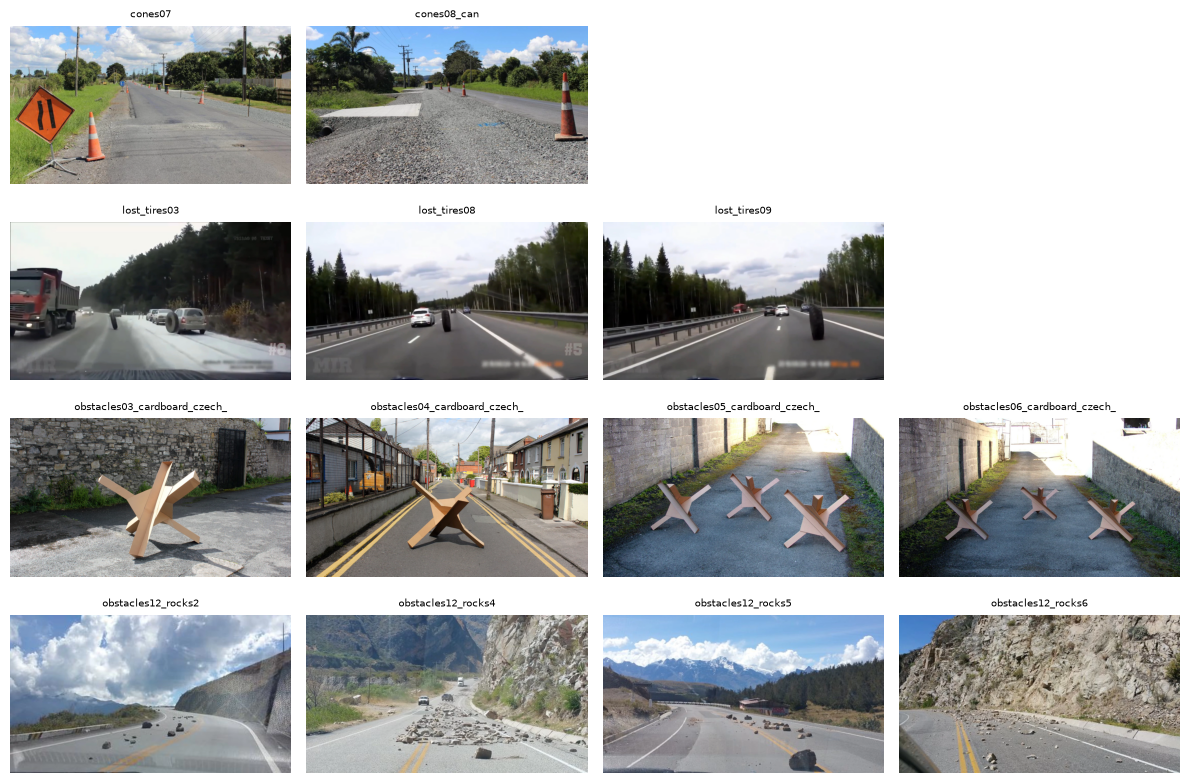

In [24]:
# Show every multi-frame group to check visually that they share scene or object
multi = [m for m in groups if len(m) > 1]
cols = max(len(m) for m in multi)
fig, ax = plt.subplots(len(multi), cols, figsize=(3 * cols, 2 * len(multi)), squeeze=False, tight_layout=True)
for i, members in enumerate(multi):
    for j in range(cols):
        ax[i, j].axis("off")
        if j < len(members):
            ax[i, j].imshow(Image.open(FRAMES_DIR / f"{members[j]}.webp"))
            ax[i, j].set_title(members[j][:28], fontsize=7)
plt.savefig(FIG_DIR / "06_scene_groups.png", dpi=70)
plt.show()

## 9. Normal data for the Autoencoder (Binôme B)
FR's autoencoder must learn to reconstruct **normal** road scenes only. Section 5 showed that no image is anomaly-free, so the only in-dataset source of normal data is **background patches**. They are counted here on all 60 images at the working resolution, to choose a patch size; notebook 3 counts them again on the final **train** split only, the only images the autoencoder may learn from.

In [25]:
# Count anomaly-free patches (all images; notebook 3 recounts them on the train split only)
def count_normal_patches(frame_list, img_size, patch, stride):
    normal, total = 0, 0
    for frame in frame_list:
        small = np.array(Image.fromarray(masks_full[frame]).resize(img_size[::-1], Image.NEAREST))
        for y in range(0, small.shape[0] - patch + 1, stride):
            for x in range(0, small.shape[1] - patch + 1, stride):
                total += 1
                normal += small[y:y + patch, x:x + patch].max() == 0
    return normal, total

rows = []
for patch in [32, 64, 96, 128]:
    normal, total = count_normal_patches(frames, IMG_SIZE, patch, patch // 2)
    rows.append({"patch": f"{patch}x{patch}", "stride": patch // 2, "patches (all 60 images)": total,
                 "anomaly-free": normal, "% anomaly-free": round(100 * normal / total, 1)})
pd.DataFrame(rows)

,patch,stride,patches (all 60 images),anomaly-free,% anomaly-free
0,32x32,16,49140,39137,79.6
1,64x64,32,11400,7852,68.9
2,96x96,48,4320,2467,57.1
3,128x128,64,2160,1049,48.6


## 10. From insights to the evaluation protocol
Each decision below comes from a measurement in this notebook. Section numbers point to the evidence.

| # | Measured insight | Consequence | Decision |
|---|---|---|---|
| 1 | All 60 images contain an anomaly. Anomaly pixels are **9.85 %** of the dataset, so predicting "all background" scores **90.15 % pixel accuracy** (§5). | Accuracy rewards a model that detects nothing. | **Pixel accuracy is not used**, not even as a Keras training metric. |
| 2 | The anomaly ratio per image ranges from **0.37 % to 42.3 %**, a factor of about 115, with a median of 6.6 % (§5). | Pooled pixel counts are dominated by a few images with huge animals. | **Primary:** the FR floor metrics (Precision, Recall, F1, IoU, Dice) as the **mean over images**. The pooled ("aggregated") scores are reported as secondary. |
| 3 | Pixel prevalence on validation is **9.07 %** (notebook 3, §2). | For a score map, AUROC has a chance level of 0.5 whatever the imbalance, so it looks good too easily. AuPRC has a chance level equal to the prevalence. | Threshold-free score maps (autoencoder error maps, model probabilities): **AuPRC is the main ranking metric**. AUROC (an FR requirement for the AE) is reported next to it with its chance level. |
| 4 | **36 / 60** images contain several obstacles. Object sizes span 16 px to 390,065 px, and **49 %** of objects are under 1000 px. In multi-object images the largest object holds **68 %** of the anomaly pixels (§6). | A model can reach a good pixel IoU while missing most obstacles, i.e. the small ones. | **Object-level scores for all three approaches** (`metrics.object_scores`): object recall (an obstacle counts as found if ≥ 50 % of it is covered), object precision (predicted blobs that are false alarms) and object F1. |
| 5 | **59** components under 16 px (20 % of all components, **0.002 %** of anomaly pixels) are isolated annotation dots, not obstacles (§6, figure 04). | They would count as missed obstacles, and they pull boundary distances (HD95) towards stray pixels. | The ground truth is **not edited** (the effect on pixel metrics is negligible). Object and boundary metrics ignore components smaller than `MIN_OBJECT_PX`: 16 px at 1280x720, which is **4 px at 352x640**, applied with `metrics.remove_small_components`. |
| 6 | Instance labels exist for only 46 / 60 frames, and they disagree with the connected components in 20 of those 46 (§6). | Instance labels cannot define "an object" for the whole dataset. | An object is a **connected component** (8-connectivity). AUPRO and the object scores use these same components. |
| 7 | At 352x640, **10.5 %** of the objects keep fewer than 16 px (§7). | The smallest obstacles are the hardest case and must not be hidden in averages. | Report object recall **separately for small (< 1000 px at full resolution, half of all objects) and large objects**. |
| 8 | Validation and test have only **9 images each** (test: 22 objects, no lost-tyre scene) (notebook 3, §1). | A one-image change moves the mean by about 11 %. | Report every test mean with a **95 % bootstrap interval over images** (`metrics.bootstrap_ci`). Don't declare a winner when the intervals overlap. Per-image results are always shown. |
| 9 | No anomaly-free image exists, but **5,488 of 7,980** 64x64 patches of the **train split** contain no anomaly at 352x640 (5,325 once each obstacle is enlarged by the 4-px training margin) (§9; notebook 3, §3). | The autoencoder can learn "normal" from background patches of the training images, without external data. | Binôme B trains on anomaly-free train patches. External normal data is added only if needed and with authorization, as FR requires. For AUPRO, state the integration limit (FPR cap). |
| 10 | Objects show no perspective size trend (correlation −0.18), and almost none are in the top third of the image (**0.8 %**) (§6). | Perspective-aware tricks are not supported by this data. The location prior is strong. | No perspective correction. Augmentation uses horizontal flips only, never vertical, and crops of at least 80 %. Errors in the upper image are analysed separately. |

**Protocol summary, common to the three binômes**
1. Data: `splits/split_manifest.csv` (built and checked in notebook 3) with `IMG_SIZE = (352, 640)`, loaded through `roadanomaly.data_pipeline`. The **test split is used once**, for the final comparison.
2. Thresholds (score → mask), early stopping and model selection use **validation only**. The default threshold maximises the per-image mean F1 on validation.
3. Required for every approach:
   - pixel Precision, Recall, F1, IoU and Dice, as per-image mean and aggregated;
   - object recall, precision and F1, overall and split into small vs large objects;
   - 95 % bootstrap intervals on the test set;
   - the pixel confusion matrix.
4. For threshold-free score maps: AuPRC (main) and AUROC (with chance level).
5. Approach-specific metrics from FR are computed on speckle-filtered masks, with units in px at 352x640 and the band width or FPR cap stated:
   - HD95 for U-Net;
   - Boundary IoU and mIoU for DeepLabV3+, the latter only if multi-class labels exist, and here they do not: the labels are binary;
   - AUPRO for the AE.

   In the end the shared report (`roadanomaly.evaluation`) computes all three for every model, so that the approaches can be compared on each of them.
6. Log for every run: seed, `IMG_SIZE`, batch size, epochs, learning rate, GPU name and TensorFlow version.

The constants of this protocol are stored once in `src/roadanomaly/protocol.py` (`IMG_SIZE`, `MIN_OBJECT_PX`, `SMALL_OBJECT_PX`, `FPR_LIMIT`, bootstrap settings), and the full report is computed by `roadanomaly.evaluation` for every model, so the three binômes cannot drift apart.

In [26]:
# The protocol module must hold exactly the values measured in this notebook
from roadanomaly import protocol

assert protocol.IMG_SIZE == IMG_SIZE
assert protocol.MIN_OBJECT_PX_FULL == MIN_OBJECT_PX
assert protocol.MIN_OBJECT_PX == MIN_OBJECT_PX_WORK
print({k: getattr(protocol, k) for k in ["SEED", "IMG_SIZE", "MIN_OBJECT_PX", "SMALL_OBJECT_PX", "FPR_LIMIT"]})

{'SEED': 1337, 'IMG_SIZE': (352, 640), 'MIN_OBJECT_PX': 4, 'SMALL_OBJECT_PX': 239, 'FPR_LIMIT': 0.3}


## 11. What this dataset supports and its limitations

| The data supports | The data does not establish |
|---|---|
| Comparing methods for **binary pixel-level anomaly segmentation** on the 60 provided images. | Multi-class pixel segmentation of animals, cones, rocks, or other anomaly categories: masks only label background vs. anomaly. |
| Analysis of image/mask resolution, anomaly-pixel imbalance, obstacle sizes, and grouped train/validation/test evaluation. | Robustness across lighting, weather, road types, or other environmental conditions. These attributes are not systematically recorded or evaluated here. |
| A controlled comparison using the shared split and validation-only model selection. | Reliable real-world performance estimates: the dataset and validation/test splits are small, so results are uncertain and may not generalize. |

The dataset occupies **about 12.53 MiB** in this repository (the notebook computes the current value at runtime). All 60 image/mask pairs were readable in the current local copy. Re-run the integrity cell if the data files change.
